# Assignment 2 - Bookstore Intelligence Mission
Website used: https://books.toscrape.com/

## Mission 1 - Reconnaissance

| Data Needed | HTML Tag / Class Found | Notes |
|---|---|---|
| Book Title | `<a>` inside `<h3>`, the `title` attribute | The text on the page is cut short, the full title is in the title attribute |
| Price | `<p class="price_color">` | Comes with a pound sign, need to remove it |
| Rating | `<p class="star-rating Three">` | The rating is a word in the second class name |
| Availability | `<p class="instock availability">` | Text is "In stock", has extra spaces |

Every book is inside an `<article class="product_pod">`.

## Mission 2 - Capture the data

In [1]:
!pip install requests beautifulsoup4 pandas matplotlib

In [2]:
import requests
from bs4 import BeautifulSoup
import pandas as pd
import matplotlib.pyplot as plt

In [3]:
response = requests.get("https://books.toscrape.com/")
print(response.status_code)

200


In [4]:
import requests
from bs4 import BeautifulSoup
import pandas as pd
import matplotlib.pyplot as plt

rating_numbers = {"One": 1, "Two": 2, "Three": 3, "Four": 4, "Five": 5}


def scrape_page(page_number):
    url = "https://books.toscrape.com/catalogue/page-" + str(page_number) + ".html"
    response = requests.get(url)
    response.encoding = "utf-8"
    soup = BeautifulSoup(response.text, "html.parser")

    books = soup.find_all("article", class_="product_pod")
    rows = []

    for book in books:
        title = book.h3.a["title"]

        price = book.find("p", class_="price_color").text
        price = float(price.replace("£", ""))

        rating_word = book.find("p", class_="star-rating")["class"][1]
        rating = rating_numbers[rating_word]

        availability = book.find("p", class_="instock availability").text.strip()

        link = "https://books.toscrape.com/catalogue/" + book.h3.a["href"]

        rows.append([title, price, rating, availability, link])

    return rows

page1 = scrape_page(1)
print(len(page1), "books found on page 1")
print(page1[0])

20 books found on page 1
['A Light in the Attic', 51.77, 3, 'In stock', 'https://books.toscrape.com/catalogue/a-light-in-the-attic_1000/index.html']


## Mission 3 - Scale the operation

In [5]:
all_books = []

for page in range(1, 6):
    print("Scraping page", page)
    all_books = all_books + scrape_page(page)

df = pd.DataFrame(all_books, columns=["Title", "Price", "Rating", "Availability", "URL"])

print(df.shape)
df.head()

Scraping page 1
Scraping page 2
Scraping page 3
Scraping page 4
Scraping page 5
(100, 5)


,Title,Price,Rating,Availability,URL
0,A Light in the Attic,51.77,3,In stock,https://books.toscrape.com/catalogue/a-light-i...
1,Tipping the Velvet,53.74,1,In stock,https://books.toscrape.com/catalogue/tipping-t...
2,Soumission,50.10,1,In stock,https://books.toscrape.com/catalogue/soumissio...
3,Sharp Objects,47.82,4,In stock,https://books.toscrape.com/catalogue/sharp-obj...
4,Sapiens: A Brief History of Humankind,54.23,5,In stock,https://books.toscrape.com/catalogue/sapiens-a...


In [6]:
# check the columns and data types
print(df.dtypes)
print(df.isnull().sum())

Title            object
Price           float64
Rating            int64
Availability     object
URL              object
dtype: object
Title           0
Price           0
Rating          0
Availability    0
URL             0
dtype: int64


In [7]:
df.to_csv("competitor_books.csv", index=False)
print("saved competitor_books.csv")

saved competitor_books.csv


## Mission 4 - Intelligence analysis

In [8]:
# Q1 most expensive book
most_expensive = df.loc[df["Price"].idxmax()]
print("Q1. Most expensive:", most_expensive["Title"], "- £" + str(most_expensive["Price"]))

# Q2 cheapest book
cheapest = df.loc[df["Price"].idxmin()]
print("Q2. Cheapest:", cheapest["Title"], "- £" + str(cheapest["Price"]))

# Q3 average price
print("Q3. Average price: £" + str(round(df["Price"].mean(), 2)))

# Q4 number of 5 star books
five_star = df[df["Rating"] == 5]
print("Q4. Number of 5-star books:", len(five_star))

# Q5 percentage in stock
in_stock = df[df["Availability"] == "In stock"]
percent = len(in_stock) / len(df) * 100
print("Q5. Percentage in stock:", round(percent, 1), "%")

Q1. Most expensive: The Death of Humanity: and the Case for Life - £58.11
Q2. Cheapest: Patience - £10.16
Q3. Average price: £34.56
Q4. Number of 5-star books: 19
Q5. Percentage in stock: 100.0 %


In [9]:
# Q6 top 5 highest rated books
# sorted by rating first and then the cheapest first
top5 = df.sort_values(["Rating", "Price"], ascending=[False, True]).head(5)
print("Q6. Top 5 highest-rated books:")
top5[["Title", "Price", "Rating"]]

Q6. Top 5 highest-rated books:


,Title,Price,Rating
81,Princess Between Worlds (Wide-Awake Princess #5),13.34,5
80,"Princess Jellyfish 2-in-1 Omnibus, Vol. 01 (Pr...",13.61,5
34,Sophie's World,15.94,5
54,Thirst,17.27,5
12,Set Me Free,17.46,5


In [ ]:
# Q7 cheapest 5 star book
cheapest_five = five_star.loc[five_star["Price"].idxmin()]
print(" Cheapest 5-star book:", cheapest_five["Title"], "- £" + str(cheapest_five["Price"]))

 Cheapest 5-star book: Princess Between Worlds (Wide-Awake Princess #5) - £13.34


## Final Challenge - The CEO has £100

Idea: each star is worth the same, so I want the most stars for every pound spent.
I worked out stars per pound for each book, sorted from best to worst, and kept
buying books while there was still enough money left.

In [10]:
df["stars_per_pound"] = df["Rating"] / df["Price"]
sorted_books = df.sort_values("stars_per_pound", ascending=False)

money_left = 100
chosen = []

for index, book in sorted_books.iterrows():
    if book["Price"] <= money_left:
        chosen.append(book)
        money_left = money_left - book["Price"]

chosen = pd.DataFrame(chosen)
print(chosen[["Title", "Price", "Rating"]].to_string(index=False))
print()
print("Total cost: £" + str(round(chosen["Price"].sum(), 2)))
print("Total rating score:", chosen["Rating"].sum())

                                                                            Title  Price  Rating
                                 Princess Between Worlds (Wide-Awake Princess #5)  13.34       5
Princess Jellyfish 2-in-1 Omnibus, Vol. 01 (Princess Jellyfish 2-in-1 Omnibus #1)  13.61       5
                                                                   Sophie's World  15.94       5
                                                                         Patience  10.16       3
                                                                           Thirst  17.27       5
                                                                      Set Me Free  17.46       5

Total cost: £87.78
Total rating score: 28


## Bonus - rating counts and chart

Rating
1    22
2    19
3    22
4    18
5    19
Name: count, dtype: int64


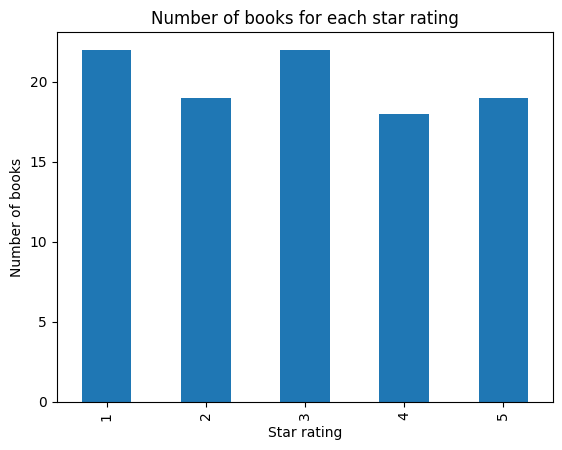

In [11]:
rating_counts = df["Rating"].value_counts().sort_index()
print(rating_counts)

rating_counts.plot(kind="bar")
plt.title("Number of books for each star rating")
plt.xlabel("Star rating")
plt.ylabel("Number of books")
plt.show()

**Business Recommendation**
The most effective strategy is to choose books with 5-star ratings priced below the average of £34.56. Of the 100 books analysed, only 19 received a 5-star rating, making them a select group of high-quality options. Books priced between £13 and £17 provide the best value for money. Since all books are in stock, availability does not offer a competitive advantage. Therefore, prioritising high ratings and affordable prices is the best approach. Under the £100 budget challenge, this strategy allowed the purchase of 6 books with a combined rating score of 28, costing a total of £87.78.